In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.decomposition import TruncatedSVD
from sklearn.preprocessing import normalize
from sklearn.cluster import KMeans
from sklearn.metrics import pairwise_distances
from scipy.sparse import csr_matrix
from scipy.sparse.linalg import svds
from collections import defaultdict
import warnings
warnings.filterwarnings("ignore")

BASE = r"D:\music-recommendation-system\data\processed"

# ── Load Phase 1 outputs ──────────────────────────────────────────
songs_df         = pd.read_csv(os.path.join(BASE, "songs_clean.csv"),      index_col=0)
history_df       = pd.read_csv(os.path.join(BASE, "history_clean.csv"))
user_item_matrix = pd.read_csv(os.path.join(BASE, "user_item_matrix.csv"), index_col=0)

# ── Load Phase 2 outputs ──────────────────────────────────────────
song_ids        = np.load(os.path.join(BASE, "song_ids.npy"),         allow_pickle=True).tolist()
unified_matrix  = np.load(os.path.join(BASE, "unified_matrix.npy"))
vector_sources  = pd.read_csv(os.path.join(BASE, "vector_sources.csv"))

# Fix is_obscure dtype (can become string after CSV save/load)
songs_df['is_obscure'] = songs_df['is_obscure'].astype(str).str.lower() == 'true'

# Fix user_item_matrix column types — must match history_df track_id type
user_item_matrix.columns = user_item_matrix.columns.astype(int)

print("Loaded:")
print(f"  songs_df:         {songs_df.shape}")
print(f"  history_df:       {history_df.shape}")
print(f"  user_item_matrix: {user_item_matrix.shape}")
print(f"  song_ids:         {len(song_ids):,}")
print(f"  unified_matrix:   {unified_matrix.shape}")

print(f"\nUsers:   {user_item_matrix.shape[0]:,}")
print(f"Songs:   {user_item_matrix.shape[1]:,}")
total    = user_item_matrix.shape[0] * user_item_matrix.shape[1]
filled   = (user_item_matrix > 0).sum().sum()
sparsity = 1 - filled / total
print(f"Sparsity: {sparsity:.1%}")

Loaded:
  songs_df:         (8000, 15)
  history_df:       (14873, 3)
  user_item_matrix: (500, 4978)
  song_ids:         8,000
  unified_matrix:   (8000, 64)

Users:   500
Songs:   4,978
Sparsity: 99.4%


In [2]:
import os

BASE = r"D:\music-recommendation-system\data\processed"
print("Files in processed folder:")
for f in sorted(os.listdir(BASE)):
    size = os.path.getsize(os.path.join(BASE, f)) / 1024
    print(f"  {f:<45} {size:>8.1f} KB")

Files in processed folder:
  audio_features.csv                              4920.8 KB
  echonest_audio_features.csv                      132.0 KB
  embedding_matrix.npy                            1406.4 KB
  faiss_audio.index                               1406.3 KB
  faiss_unified.index                             2000.0 KB
  genres_clean.csv                                   4.0 KB
  history_clean.csv                                281.4 KB
  song_ids.npy                                      31.4 KB
  songs_clean.csv                                 1473.3 KB
  unified_matrix.npy                              2000.1 KB
  user_item_matrix.csv                            9759.7 KB
  vector_sources.csv                               128.0 KB
  vectors_audio.npy                               1406.4 KB
  vectors_unified.npy                             2000.1 KB
  word2vec_model.bin                              4226.7 KB


USER STATS
Total users:          500
Avg plays per user:   83.7
Avg songs per user:   29.7
Max songs per user:   50
Min songs per user:   10

=== SONG STATS ===
Songs with interactions: 4,978
Avg plays per song:      8.4
Avg users per song:      3.0
Max users per song:      167


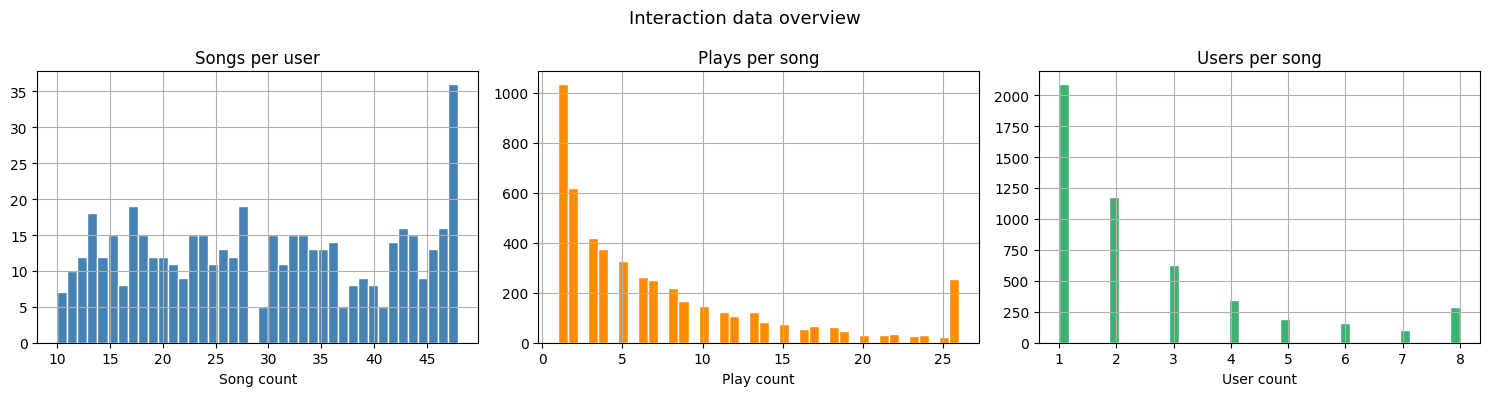

In [3]:
print("USER STATS")
plays_per_user = history_df.groupby('user_id')['plays'].sum()
songs_per_user = history_df.groupby('user_id')['track_id'].count()

print(f"Total users:          {history_df['user_id'].nunique():,}")
print(f"Avg plays per user:   {plays_per_user.mean():.1f}")
print(f"Avg songs per user:   {songs_per_user.mean():.1f}")
print(f"Max songs per user:   {songs_per_user.max()}")
print(f"Min songs per user:   {songs_per_user.min()}")

print("\n=== SONG STATS ===")
plays_per_song = history_df.groupby('track_id')['plays'].sum()
users_per_song = history_df.groupby('track_id')['user_id'].count()

print(f"Songs with interactions: {history_df['track_id'].nunique():,}")
print(f"Avg plays per song:      {plays_per_song.mean():.1f}")
print(f"Avg users per song:      {users_per_song.mean():.1f}")
print(f"Max users per song:      {users_per_song.max()}")

# Visualize
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
fig.suptitle('Interaction data overview', fontsize=13)

songs_per_user.clip(upper=songs_per_user.quantile(0.95)).hist(
    bins=40, ax=axes[0], color='steelblue', edgecolor='white')
axes[0].set_title('Songs per user')
axes[0].set_xlabel('Song count')

plays_per_song.clip(upper=plays_per_song.quantile(0.95)).hist(
    bins=40, ax=axes[1], color='darkorange', edgecolor='white')
axes[1].set_title('Plays per song')
axes[1].set_xlabel('Play count')

users_per_song.clip(upper=users_per_song.quantile(0.95)).hist(
    bins=40, ax=axes[2], color='mediumseagreen', edgecolor='white')
axes[2].set_title('Users per song')
axes[2].set_xlabel('User count')

plt.tight_layout()
plt.savefig(os.path.join(BASE, "interaction_overview.png"), dpi=120, bbox_inches='tight')
plt.show()

In [4]:
# Convert user_item_matrix to scipy sparse format
# Much faster for SVD and uses far less RAM

matrix_values = user_item_matrix.values.astype('float32')
sparse_matrix = csr_matrix(matrix_values)

user_ids = user_item_matrix.index.tolist()
item_ids = user_item_matrix.columns.tolist()  # track_ids

# Mappings
user_to_idx = {uid: i for i, uid in enumerate(user_ids)}
idx_to_user = {i: uid for i, uid in enumerate(user_ids)}
item_to_idx = {iid: i for i, iid in enumerate(item_ids)}
idx_to_item = {i: iid for i, iid in enumerate(item_ids)}

print(f"Sparse matrix shape:   {sparse_matrix.shape}")
print(f"Non-zero elements:     {sparse_matrix.nnz:,}")
print(f"Density:               {sparse_matrix.nnz / (sparse_matrix.shape[0] * sparse_matrix.shape[1]):.2%}")
print(f"Memory (sparse):       {sparse_matrix.data.nbytes / 1024:.1f} KB")
print(f"Memory (dense):        {matrix_values.nbytes / 1024 / 1024:.1f} MB")
print(f"\nUser IDs sample:  {user_ids[:3]}")
print(f"Item IDs sample:  {item_ids[:3]}")

Sparse matrix shape:   (500, 4978)
Non-zero elements:     14,873
Density:               0.60%
Memory (sparse):       58.1 KB
Memory (dense):        9.5 MB

User IDs sample:  ['user_0000', 'user_0001', 'user_0002']
Item IDs sample:  [2, 5, 10]


Running SVD matrix factorization...
SVD complete
  U shape (users × factors):  (500, 50)
  sigma shape (factors):      (50,)
  Vt shape (factors × songs): (50, 4978)

Top 10 singular values (importance of each factor):
[69.36 52.73 45.32 43.26 42.52 41.57 40.42 39.91 38.97 38.34]

Variance explained:
  Top 10 factors: 25.1%
  Top 20 factors: 45.4%
  All 50 factors:  100.0%


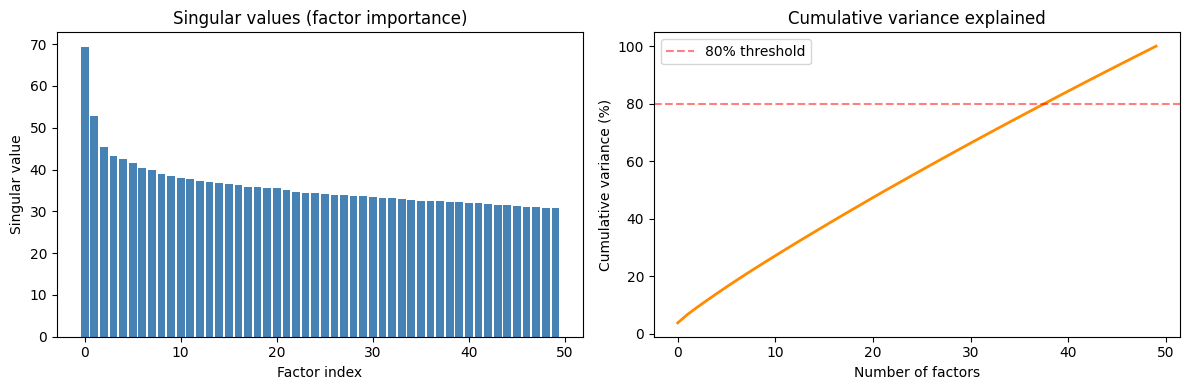

In [5]:
print("Running SVD matrix factorization...")

# k = number of latent factors
# Higher k = more expressive but slower and risks overfitting
# 50 is a good starting point for 500 users × 8000 songs
k = 50

# svds returns U, sigma, Vt
# U     shape: (users, k)   — user latent factors
# sigma shape: (k,)         — importance of each factor
# Vt    shape: (k, songs)   — song latent factors
U, sigma, Vt = svds(sparse_matrix, k=k)

# svds returns smallest singular values first — reverse for descending order
U     = U[:, ::-1]
sigma = sigma[::-1]
Vt    = Vt[::-1, :]

print(f"SVD complete")
print(f"  U shape (users × factors):  {U.shape}")
print(f"  sigma shape (factors):      {sigma.shape}")
print(f"  Vt shape (factors × songs): {Vt.shape}")
print(f"\nTop 10 singular values (importance of each factor):")
print(np.round(sigma[:10], 2))

# Variance explained — how much of the data each factor captures
total_var    = sigma.sum()
var_per_comp = sigma / total_var * 100
cumvar       = np.cumsum(var_per_comp)
print(f"\nVariance explained:")
print(f"  Top 10 factors: {cumvar[9]:.1f}%")
print(f"  Top 20 factors: {cumvar[19]:.1f}%")
print(f"  All {k} factors:  {cumvar[-1]:.1f}%")

# Plot singular values
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].bar(range(k), sigma, color='steelblue')
axes[0].set_title('Singular values (factor importance)')
axes[0].set_xlabel('Factor index')
axes[0].set_ylabel('Singular value')

axes[1].plot(range(k), cumvar, color='darkorange', linewidth=2)
axes[1].axhline(y=80, color='red', linestyle='--', alpha=0.5, label='80% threshold')
axes[1].set_title('Cumulative variance explained')
axes[1].set_xlabel('Number of factors')
axes[1].set_ylabel('Cumulative variance (%)')
axes[1].legend()

plt.tight_layout()
plt.savefig(os.path.join(BASE, "svd_factors.png"), dpi=120, bbox_inches='tight')
plt.show()

In [6]:
# Reconstruct the full predicted rating matrix
# predicted[i][j] = model's estimate of how much user i would like song j
sigma_diag       = np.diag(sigma)
predicted_matrix = np.dot(np.dot(U, sigma_diag), Vt)

print(f"Predicted matrix shape: {predicted_matrix.shape}")
print(f"Value range: [{predicted_matrix.min():.3f}, {predicted_matrix.max():.3f}]")

# Convert to DataFrame for easy lookup
predicted_df = pd.DataFrame(
    predicted_matrix,
    index=user_ids,
    columns=item_ids
)

print(f"\nPredicted ratings DataFrame: {predicted_df.shape}")

# Sanity check — check a user who actually listened to something
sample_user = user_ids[0]
actual_plays = user_item_matrix.loc[sample_user]
predicted_plays = predicted_df.loc[sample_user]

actual_songs    = actual_plays[actual_plays > 0].index.tolist()
print(f"\nUser '{sample_user}':")
print(f"  Actually listened to: {len(actual_songs)} songs")
print(f"  Predicted scores range: [{predicted_plays.min():.3f}, {predicted_plays.max():.3f}]")
print(f"\nActual vs predicted for listened songs (first 5):")
for sid in actual_songs[:5]:
    actual    = actual_plays[sid]
    predicted = predicted_plays[sid]
    title     = songs_df.loc[sid, 'title'] if sid in songs_df.index else str(sid)
    print(f"  {str(title)[:35]:<35}  actual: {actual:.0f}  predicted: {predicted:.3f}")

Predicted matrix shape: (500, 4978)
Value range: [-2.368, 24.244]

Predicted ratings DataFrame: (500, 4978)

User 'user_0000':
  Actually listened to: 48 songs
  Predicted scores range: [-1.268, 3.611]

Actual vs predicted for listened songs (first 5):
  Freeway                              actual: 2  predicted: 0.702
  Reindeer Dance                       actual: 1  predicted: 0.702
  Track 01                             actual: 5  predicted: 0.823
  New Wave Hippies                     actual: 3  predicted: 0.435
  Telegrafin Tellerine                 actual: 1  predicted: 0.139


In [7]:
def recommend_cf(user_id, top_n=10, exclude_listened=True):
    """
    Recommend songs for a user using SVD collaborative filtering.

    user_id          : must be in user_item_matrix index
    top_n            : number of recommendations
    exclude_listened : if True, don't recommend songs user already played
    """
    if user_id not in predicted_df.index:
        print(f"User '{user_id}' not found")
        return None

    scores = predicted_df.loc[user_id].copy()

    if exclude_listened:
        # Remove songs the user already played
        already_played = user_item_matrix.loc[user_id]
        listened_ids   = already_played[already_played > 0].index.tolist()
        scores         = scores.drop(labels=listened_ids, errors='ignore')

    top = scores.sort_values(ascending=False).head(top_n)

    results = []
    for track_id, score in top.items():
        row = {
            'track_id':  track_id,
            'cf_score':  round(float(score), 4),
        }
        if track_id in songs_df.index:
            row['title']   = str(songs_df.loc[track_id, 'title'])[:40]
            row['artist']  = str(songs_df.loc[track_id, 'artist_name'])[:25]
            row['listens'] = int(songs_df.loc[track_id, 'listens'])
            row['genre']   = str(songs_df.loc[track_id, 'genre_top'])
            row['obscure'] = bool(songs_df.loc[track_id, 'is_obscure'])
        results.append(row)

    return pd.DataFrame(results)


# Test it
sample_user = user_ids[0]
print(f"CF recommendations for user: '{sample_user}'")
print("-" * 65)
recs = recommend_cf(sample_user, top_n=10)
if recs is not None:
    print(recs[['title', 'artist', 'genre', 'cf_score', 'obscure']].to_string(index=False))

print(f"\nListened to {len(user_item_matrix.loc[sample_user][user_item_matrix.loc[sample_user]>0])} songs")
print(f"Recommended {len(recs)} new songs")

CF recommendations for user: 'user_0000'
-----------------------------------------------------------------
               title            artist        genre  cf_score  obscure
               No.02  Room For A Ghost         Rock    2.2863    False
            Be Sweet  Marco Trovatello         Rock    1.9727    False
        Love Sprouts    Podington Bear Instrumental    1.6914    False
  Adventure, Darling        Gillicuddy Instrumental    1.6551    False
raw instrumental pt2    Digi G'Alessio   Electronic    1.6481    False
       11 strANGE Ls         Mark Neil Instrumental    1.3217    False
        House Arrest         Cory Gray Instrumental    1.1931    False
       Deep Sky Blue   Graphiqs Groove   Electronic    1.1642    False
    Under The Sunset Lesbian Afternoon          Pop    1.1545    False
  Simple Jungle List        Lantriperc   Electronic    1.1099    False

Listened to 48 songs
Recommended 10 new songs


In [8]:
# U matrix gives each user a k-dimensional "taste vector"
# Similar users have similar taste vectors

user_factors = pd.DataFrame(
    U,
    index=user_ids,
    columns=[f'factor_{i}' for i in range(k)]
)

print(f"User factor matrix: {user_factors.shape}")
print(f"Each user represented as a {k}-dimensional taste vector")

# Song latent factors — rows of Vt scaled by sigma
song_factors = pd.DataFrame(
    (np.diag(sigma) @ Vt).T,
    index=item_ids,
    columns=[f'factor_{i}' for i in range(k)]
)

print(f"Song factor matrix: {song_factors.shape}")

# Find most similar users to a given user
from sklearn.metrics.pairwise import cosine_similarity as cos_sim

def find_similar_users(user_id, top_n=5):
    if user_id not in user_to_idx:
        return None

    user_vec   = user_factors.loc[user_id].values.reshape(1, -1)
    all_vecs   = user_factors.values
    sims       = cos_sim(user_vec, all_vecs)[0]
    sim_series = pd.Series(sims, index=user_ids)
    sim_series = sim_series.drop(user_id)

    return sim_series.sort_values(ascending=False).head(top_n)


print(f"\nUsers most similar to '{user_ids[0]}':")
similar_users = find_similar_users(user_ids[0], top_n=5)
print(similar_users)

User factor matrix: (500, 50)
Each user represented as a 50-dimensional taste vector
Song factor matrix: (4978, 50)

Users most similar to 'user_0000':
user_0198    0.710266
user_0445    0.637256
user_0328    0.470747
user_0297    0.465188
user_0400    0.460296
dtype: float32


In [9]:
def recommend_cf(user_id, top_n=10, exclude_listened=True):
    """
    Recommend songs for a user using SVD collaborative filtering.

    user_id          : must be in user_item_matrix index
    top_n            : number of recommendations
    exclude_listened : if True, don't recommend songs user already played
    """
    if user_id not in predicted_df.index:
        print(f"User '{user_id}' not found")
        return None

    scores = predicted_df.loc[user_id].copy()

    if exclude_listened:
        # Remove songs the user already played
        already_played = user_item_matrix.loc[user_id]
        listened_ids   = already_played[already_played > 0].index.tolist()
        scores         = scores.drop(labels=listened_ids, errors='ignore')

    top = scores.sort_values(ascending=False).head(top_n)

    results = []
    for track_id, score in top.items():
        row = {
            'track_id':  track_id,
            'cf_score':  round(float(score), 4),
        }
        if track_id in songs_df.index:
            row['title']   = str(songs_df.loc[track_id, 'title'])[:40]
            row['artist']  = str(songs_df.loc[track_id, 'artist_name'])[:25]
            row['listens'] = int(songs_df.loc[track_id, 'listens'])
            row['genre']   = str(songs_df.loc[track_id, 'genre_top'])
            row['obscure'] = bool(songs_df.loc[track_id, 'is_obscure'])
        results.append(row)

    return pd.DataFrame(results)


# Test it
sample_user = user_ids[0]
print(f"CF recommendations for user: '{sample_user}'")
print("-" * 65)
recs = recommend_cf(sample_user, top_n=10)
if recs is not None:
    print(recs[['title', 'artist', 'genre', 'cf_score', 'obscure']].to_string(index=False))

print(f"\nListened to {len(user_item_matrix.loc[sample_user][user_item_matrix.loc[sample_user]>0])} songs")
print(f"Recommended {len(recs)} new songs")

CF recommendations for user: 'user_0000'
-----------------------------------------------------------------
               title            artist        genre  cf_score  obscure
               No.02  Room For A Ghost         Rock    2.2863    False
            Be Sweet  Marco Trovatello         Rock    1.9727    False
        Love Sprouts    Podington Bear Instrumental    1.6914    False
  Adventure, Darling        Gillicuddy Instrumental    1.6551    False
raw instrumental pt2    Digi G'Alessio   Electronic    1.6481    False
       11 strANGE Ls         Mark Neil Instrumental    1.3217    False
        House Arrest         Cory Gray Instrumental    1.1931    False
       Deep Sky Blue   Graphiqs Groove   Electronic    1.1642    False
    Under The Sunset Lesbian Afternoon          Pop    1.1545    False
  Simple Jungle List        Lantriperc   Electronic    1.1099    False

Listened to 48 songs
Recommended 10 new songs


In [10]:
# U matrix gives each user a k-dimensional "taste vector"
# Similar users have similar taste vectors

user_factors = pd.DataFrame(
    U,
    index=user_ids,
    columns=[f'factor_{i}' for i in range(k)]
)

print(f"User factor matrix: {user_factors.shape}")
print(f"Each user represented as a {k}-dimensional taste vector")

# Song latent factors — rows of Vt scaled by sigma
song_factors = pd.DataFrame(
    (np.diag(sigma) @ Vt).T,
    index=item_ids,
    columns=[f'factor_{i}' for i in range(k)]
)

print(f"Song factor matrix: {song_factors.shape}")

# Find most similar users to a given user
from sklearn.metrics.pairwise import cosine_similarity as cos_sim

def find_similar_users(user_id, top_n=5):
    if user_id not in user_to_idx:
        return None

    user_vec   = user_factors.loc[user_id].values.reshape(1, -1)
    all_vecs   = user_factors.values
    sims       = cos_sim(user_vec, all_vecs)[0]
    sim_series = pd.Series(sims, index=user_ids)
    sim_series = sim_series.drop(user_id)

    return sim_series.sort_values(ascending=False).head(top_n)


print(f"\nUsers most similar to '{user_ids[0]}':")
similar_users = find_similar_users(user_ids[0], top_n=5)
print(similar_users)

User factor matrix: (500, 50)
Each user represented as a 50-dimensional taste vector
Song factor matrix: (4978, 50)

Users most similar to 'user_0000':
user_0198    0.710266
user_0445    0.637256
user_0328    0.470747
user_0297    0.465188
user_0400    0.460296
dtype: float32


In [11]:
def recommend_user_user_cf(user_id, top_n=10, n_similar_users=20):
    """
    Recommend songs by finding similar users and aggregating their listening history.
    Different from SVD — directly uses user-to-user similarity.
    """
    if user_id not in user_to_idx:
        print(f"User '{user_id}' not found")
        return None

    # Find similar users using latent factors
    similar = find_similar_users(user_id, top_n=n_similar_users)
    similar_user_ids = similar.index.tolist()
    similarity_weights = similar.values

    # Songs the target user already played
    already_played = set(
        user_item_matrix.loc[user_id][user_item_matrix.loc[user_id] > 0].index.tolist()
    )

    # Weighted sum of similar users' play counts
    song_scores = defaultdict(float)
    for sim_uid, weight in zip(similar_user_ids, similarity_weights):
        sim_plays = user_item_matrix.loc[sim_uid]
        for track_id, play_count in sim_plays.items():
            if play_count > 0 and track_id not in already_played:
                song_scores[track_id] += weight * play_count

    if not song_scores:
        return None

    # Sort and return top_n
    sorted_songs = sorted(song_scores.items(), key=lambda x: x[1], reverse=True)
    results = []
    for track_id, score in sorted_songs[:top_n]:
        row = {
            'track_id': track_id,
            'uu_score': round(float(score), 4),
        }
        if track_id in songs_df.index:
            row['title']   = str(songs_df.loc[track_id, 'title'])[:40]
            row['artist']  = str(songs_df.loc[track_id, 'artist_name'])[:25]
            row['listens'] = int(songs_df.loc[track_id, 'listens'])
            row['genre']   = str(songs_df.loc[track_id, 'genre_top'])
            row['obscure'] = bool(songs_df.loc[track_id, 'is_obscure'])
        results.append(row)

    return pd.DataFrame(results)


# Test it
print(f"User-User CF for '{user_ids[0]}':")
print("-" * 65)
recs_uu = recommend_user_user_cf(user_ids[0], top_n=10)
if recs_uu is not None:
    print(recs_uu[['title', 'artist', 'genre', 'uu_score', 'obscure']].to_string(index=False))

User-User CF for 'user_0000':
-----------------------------------------------------------------
               title           artist        genre  uu_score  obscure
            Be Sweet Marco Trovatello         Rock   10.8132    False
               No.02 Room For A Ghost         Rock    9.0374    False
raw instrumental pt2   Digi G'Alessio   Electronic    8.4448    False
           Night Owl   Broke For Free   Electronic    8.1433    False
                 aaf           Goto80   Electronic    7.3947    False
           wild tape        Amy Sayer         Folk    7.0559    False
        Love Sprouts   Podington Bear Instrumental    7.0098    False
           Lope-Trip   Podington Bear Instrumental    6.2213    False
          La Barcaza       Ø+yn + GMC Experimental    5.6981    False
       11 strANGE Ls        Mark Neil Instrumental    5.0998    False


In [12]:
import faiss

# Load Phase 2 FAISS index
vectors_unified = np.load(os.path.join(BASE, "vectors_unified.npy"))
index_unified   = faiss.read_index(os.path.join(BASE, "faiss_unified.index"))
id_to_idx       = {sid: i for i, sid in enumerate(song_ids)}
idx_to_id       = {i: sid for i, sid in enumerate(song_ids)}

def recommend_hybrid(user_id, top_n=10, cf_weight=0.6, embed_weight=0.4):
    """
    Hybrid recommendation combining:
      - SVD collaborative filtering score  (cf_weight)
      - Audio/W2V embedding similarity     (embed_weight)

    For obscure songs, embed_weight is automatically increased
    because CF has little data for them.

    cf_weight + embed_weight should = 1.0
    """
    if user_id not in predicted_df.index:
        print(f"User '{user_id}' not found")
        return None

    already_played = set(
        user_item_matrix.loc[user_id][user_item_matrix.loc[user_id] > 0].index.tolist()
    )

    # ── CF scores ────────────────────────────────────────────────
    cf_scores = predicted_df.loc[user_id].copy()
    cf_scores = cf_scores.drop(labels=list(already_played), errors='ignore')

    # Normalize CF scores to 0-1
    cf_min, cf_max = cf_scores.min(), cf_scores.max()
    if cf_max > cf_min:
        cf_scores = (cf_scores - cf_min) / (cf_max - cf_min)

    # ── Embedding scores ─────────────────────────────────────────
    # Use the centroid of songs the user listened to as their "taste vector"
    listened_song_ids = list(already_played)
    listened_indices  = [id_to_idx[sid] for sid in listened_song_ids
                         if sid in id_to_idx]

    if not listened_indices:
        # No listening history — fall back to pure CF
        top = cf_scores.sort_values(ascending=False).head(top_n)
        results = []
        for track_id, score in top.items():
            row = {'track_id': track_id, 'hybrid_score': round(float(score), 4),
                   'method': 'cf_only'}
            if track_id in songs_df.index:
                row['title']   = str(songs_df.loc[track_id, 'title'])[:40]
                row['artist']  = str(songs_df.loc[track_id, 'artist_name'])[:25]
                row['genre']   = str(songs_df.loc[track_id, 'genre_top'])
                row['obscure'] = bool(songs_df.loc[track_id, 'is_obscure'])
            results.append(row)
        return pd.DataFrame(results)

    # Centroid = average of all listened song vectors
    listened_vecs = vectors_unified[listened_indices]
    user_centroid = listened_vecs.mean(axis=0).reshape(1, -1).astype('float32')
    faiss.normalize_L2(user_centroid)

    # Search top candidates by embedding similarity
    n_candidates = min(top_n * 10, len(song_ids))
    dists, idxs  = index_unified.search(user_centroid, n_candidates)

    embed_scores = {}
    for dist, idx in zip(dists[0], idxs[0]):
        tid = idx_to_id[idx]
        if tid not in already_played:
            embed_scores[tid] = float(dist)

    # ── Combine scores ───────────────────────────────────────────
    all_candidates = set(cf_scores.index.tolist()) | set(embed_scores.keys())
    combined = {}

    for tid in all_candidates:
        cf_s    = float(cf_scores.get(tid, 0))
        emb_s   = embed_scores.get(tid, 0)

        # Boost embedding weight for obscure songs
        is_obs  = songs_df.loc[tid, 'is_obscure'] if tid in songs_df.index else False
        if is_obs:
            w_cf, w_emb = 0.3, 0.7   # lean on audio for obscure
        else:
            w_cf, w_emb = cf_weight, embed_weight

        combined[tid] = w_cf * cf_s + w_emb * emb_s

    # Sort and return top_n
    sorted_candidates = sorted(combined.items(), key=lambda x: x[1], reverse=True)
    results = []
    for track_id, score in sorted_candidates[:top_n]:
        row = {
            'track_id':     track_id,
            'hybrid_score': round(score, 4),
            'cf_score':     round(float(cf_scores.get(track_id, 0)), 4),
            'embed_score':  round(embed_scores.get(track_id, 0), 4),
        }
        if track_id in songs_df.index:
            row['title']   = str(songs_df.loc[track_id, 'title'])[:40]
            row['artist']  = str(songs_df.loc[track_id, 'artist_name'])[:25]
            row['genre']   = str(songs_df.loc[track_id, 'genre_top'])
            row['obscure'] = bool(songs_df.loc[track_id, 'is_obscure'])
        results.append(row)

    return pd.DataFrame(results)


# Test hybrid
print(f"HYBRID recommendations for '{user_ids[0]}':")
print("-" * 70)
recs_hybrid = recommend_hybrid(user_ids[0], top_n=10)
if recs_hybrid is not None:
    print(recs_hybrid[['title', 'artist', 'genre',
                        'hybrid_score', 'obscure']].to_string(index=False))

HYBRID recommendations for 'user_0000':
----------------------------------------------------------------------
                            title           artist        genre  hybrid_score  obscure
                            No.02 Room For A Ghost         Rock        0.9691    False
                         Be Sweet Marco Trovatello         Rock        0.9392    False
               Adventure, Darling       Gillicuddy Instrumental        0.8846    False
                    11 strANGE Ls        Mark Neil Instrumental        0.8288    False
                    Deep Sky Blue  Graphiqs Groove   Electronic        0.7998    False
                          Kopeika              et_         Rock        0.7553    False
                        Night Owl   Broke For Free   Electronic        0.7444    False
                          Starkey            Koona   Electronic        0.7421    False
                            Sorry      Comfort Fit      Hip-Hop        0.7376    False
Squinting at the Su

Clustering users by taste...


  File "c:\Users\Pranav\AppData\Local\Programs\Python\Python310\lib\site-packages\joblib\externals\loky\backend\context.py", line 257, in _count_physical_cores
    cpu_info = subprocess.run(
  File "c:\Users\Pranav\AppData\Local\Programs\Python\Python310\lib\subprocess.py", line 501, in run
    with Popen(*popenargs, **kwargs) as process:
  File "c:\Users\Pranav\AppData\Local\Programs\Python\Python310\lib\subprocess.py", line 969, in __init__
    self._execute_child(args, executable, preexec_fn, close_fds,
  File "c:\Users\Pranav\AppData\Local\Programs\Python\Python310\lib\subprocess.py", line 1438, in _execute_child
    hp, ht, pid, tid = _winapi.CreateProcess(executable, args,


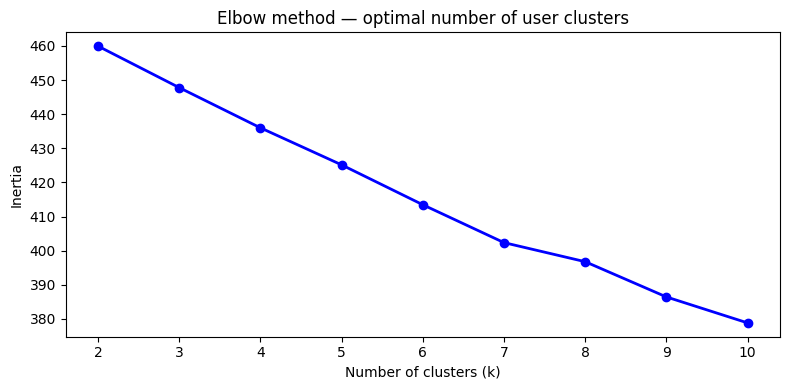


User clusters (k=5):
cluster
0    230
1     49
2     56
3    108
4     57
Name: count, dtype: int64

Users per cluster:
  Cluster 0: 230 users
  Cluster 1: 49 users
  Cluster 2: 56 users
  Cluster 3: 108 users
  Cluster 4: 57 users


In [13]:
print("Clustering users by taste...")

# Normalize user factor vectors before clustering
user_vecs_norm = normalize(U, norm='l2')

# Find optimal k using elbow method
inertias = []
k_range  = range(2, 11)

for k_val in k_range:
    km = KMeans(n_clusters=k_val, random_state=42, n_init=10)
    km.fit(user_vecs_norm)
    inertias.append(km.inertia_)

# Plot elbow
plt.figure(figsize=(8, 4))
plt.plot(list(k_range), inertias, 'bo-', linewidth=2, markersize=6)
plt.title('Elbow method — optimal number of user clusters')
plt.xlabel('Number of clusters (k)')
plt.ylabel('Inertia')
plt.xticks(list(k_range))
plt.tight_layout()
plt.savefig(os.path.join(BASE, "kmeans_elbow.png"), dpi=120)
plt.show()

# Choose k — look at elbow in the plot, usually 4-6 for small datasets
best_k = 5
kmeans = KMeans(n_clusters=best_k, random_state=42, n_init=10)
user_clusters = kmeans.fit_predict(user_vecs_norm)

cluster_df = pd.DataFrame({
    'user_id': user_ids,
    'cluster': user_clusters
})

print(f"\nUser clusters (k={best_k}):")
print(cluster_df['cluster'].value_counts().sort_index())
print(f"\nUsers per cluster:")
for c in range(best_k):
    n = (cluster_df['cluster'] == c).sum()
    print(f"  Cluster {c}: {n:,} users")

In [14]:
def precision_at_k(user_id, k=10, test_fraction=0.2):
    """
    Hold out test_fraction of a user's listened songs.
    Recommend top-k, measure how many held-out songs appear.
    """
    if user_id not in user_item_matrix.index:
        return None

    # All songs this user listened to
    played = user_item_matrix.loc[user_id]
    played = played[played > 0].index.tolist()

    if len(played) < 5:
        return None   # not enough data to split

    # Split into train (keep in matrix) and test (hold out)
    n_test       = max(1, int(len(played) * test_fraction))
    test_songs   = set(np.random.choice(played, size=n_test, replace=False))
    train_songs  = set(played) - test_songs

    # Temporarily zero out test songs for this user
    temp_row = user_item_matrix.loc[user_id].copy()
    for sid in test_songs:
        temp_row[sid] = 0

    # Get CF recommendations based on training songs only
    cf_scores    = predicted_df.loc[user_id].copy()
    cf_scores    = cf_scores.drop(labels=list(train_songs), errors='ignore')
    top_k        = cf_scores.sort_values(ascending=False).head(k).index.tolist()

    # Precision = how many of our top-k recommendations were in held-out test set
    hits         = len(set(top_k) & test_songs)
    precision    = hits / k
    recall       = hits / len(test_songs) if test_songs else 0

    return {'precision': precision, 'recall': recall, 'hits': hits}


# Evaluate across all users
print("Evaluating Precision@10 across all users...")
np.random.seed(42)

precisions = []
recalls    = []

for uid in user_ids:
    result = precision_at_k(uid, k=10, test_fraction=0.2)
    if result is not None:
        precisions.append(result['precision'])
        recalls.append(result['recall'])

print(f"\nEvaluation across {len(precisions):,} users:")
print(f"  Precision@10:  {np.mean(precisions):.4f}  ({np.mean(precisions):.1%})")
print(f"  Recall@10:     {np.mean(recalls):.4f}    ({np.mean(recalls):.1%})")
print(f"  F1@10:         {2 * np.mean(precisions) * np.mean(recalls) / (np.mean(precisions) + np.mean(recalls) + 1e-9):.4f}")
print(f"\n  (Random baseline precision: {1/len(item_ids):.4f})")
print(f"  (Lift over random: {np.mean(precisions) / (1/len(item_ids)):.1f}×)")

Evaluating Precision@10 across all users...

Evaluation across 500 users:
  Precision@10:  0.1118  (11.2%)
  Recall@10:     0.1898    (19.0%)
  F1@10:         0.1407

  (Random baseline precision: 0.0002)
  (Lift over random: 556.5×)


In [15]:
print("Comparing CF, User-User CF, and Hybrid for 3 sample users")
print("=" * 70)

for uid in user_ids[:3]:
    n_listened = (user_item_matrix.loc[uid] > 0).sum()
    print(f"\nUser: '{uid}'  |  Songs listened: {n_listened}")
    print("-" * 70)

    # SVD CF
    r1 = recommend_cf(uid, top_n=5)
    print("SVD Collaborative Filtering:")
    if r1 is not None:
        print(r1[['title', 'genre', 'cf_score', 'obscure']].to_string(index=False))
    else:
        print("  No recommendations")

    # User-User CF
    r2 = recommend_user_user_cf(uid, top_n=5)
    print("\nUser-User CF:")
    if r2 is not None:
        print(r2[['title', 'genre', 'uu_score', 'obscure']].to_string(index=False))
    else:
        print("  No recommendations")

    # Hybrid
    r3 = recommend_hybrid(uid, top_n=5)
    print("\nHybrid (CF + embeddings):")
    if r3 is not None:
        print(r3[['title', 'genre', 'hybrid_score', 'obscure']].to_string(index=False))
    else:
        print("  No recommendations")

    print()

Comparing CF, User-User CF, and Hybrid for 3 sample users

User: 'user_0000'  |  Songs listened: 48
----------------------------------------------------------------------
SVD Collaborative Filtering:
               title        genre  cf_score  obscure
               No.02         Rock    2.2863    False
            Be Sweet         Rock    1.9727    False
        Love Sprouts Instrumental    1.6914    False
  Adventure, Darling Instrumental    1.6551    False
raw instrumental pt2   Electronic    1.6481    False

User-User CF:
               title      genre  uu_score  obscure
            Be Sweet       Rock   10.8132    False
               No.02       Rock    9.0374    False
raw instrumental pt2 Electronic    8.4448    False
           Night Owl Electronic    8.1433    False
                 aaf Electronic    7.3947    False

Hybrid (CF + embeddings):
             title        genre  hybrid_score  obscure
          Be Sweet         Rock        0.9392    False
Adventure, Darling Instr

In [16]:
os.makedirs(BASE, exist_ok=True)

# User and song latent factors
user_factors.to_csv(os.path.join(BASE, "user_factors.csv"))
song_factors.to_csv(os.path.join(BASE, "song_factors.csv"))

# Predicted rating matrix
predicted_df.to_csv(os.path.join(BASE, "predicted_ratings.csv"))

# User clusters
cluster_df.to_csv(os.path.join(BASE, "user_clusters.csv"), index=False)

# SVD components (for reloading without retraining)
np.save(os.path.join(BASE, "svd_U.npy"),     U)
np.save(os.path.join(BASE, "svd_sigma.npy"), sigma)
np.save(os.path.join(BASE, "svd_Vt.npy"),    Vt)

# Evaluation results
pd.DataFrame({
    'metric':    ['precision@10', 'recall@10'],
    'svd_cf':    [np.mean(precisions), np.mean(recalls)],
    'baseline':  [1/len(item_ids), 1/len(item_ids)]
}).to_csv(os.path.join(BASE, "phase3_evaluation.csv"), index=False)

print("Saved to:", BASE)
print()
print("  user_factors.csv         — user latent factors (U matrix)")
print("  song_factors.csv         — song latent factors (Vt matrix)")
print("  predicted_ratings.csv    — full predicted rating matrix")
print("  user_clusters.csv        — K-Means user taste clusters")
print("  svd_U.npy                — SVD U matrix")
print("  svd_sigma.npy            — SVD sigma values")
print("  svd_Vt.npy               — SVD Vt matrix")
print("  phase3_evaluation.csv    — precision and recall scores")

print(f"\n{'='*55}")
print("PHASE 3 COMPLETE")
print(f"{'='*55}")
print(f"Users:              {len(user_ids):,}")
print(f"Songs:              {len(item_ids):,}")
print(f"Latent factors:     {k}")
print(f"User clusters:      {best_k}")
print(f"Precision@10:       {np.mean(precisions):.1%}")
print(f"Recall@10:          {np.mean(recalls):.1%}")
print(f"Lift over random:   {np.mean(precisions)/(1/len(item_ids)):.1f}×")
print(f"{'='*55}")

Saved to: D:\music-recommendation-system\data\processed

  user_factors.csv         — user latent factors (U matrix)
  song_factors.csv         — song latent factors (Vt matrix)
  predicted_ratings.csv    — full predicted rating matrix
  user_clusters.csv        — K-Means user taste clusters
  svd_U.npy                — SVD U matrix
  svd_sigma.npy            — SVD sigma values
  svd_Vt.npy               — SVD Vt matrix
  phase3_evaluation.csv    — precision and recall scores

PHASE 3 COMPLETE
Users:              500
Songs:              4,978
Latent factors:     50
User clusters:      5
Precision@10:       11.2%
Recall@10:          19.0%
Lift over random:   556.5×
